# Null-space refinement: calibration and held-out stress tests

**Question:** Across held-out M12 cohorts, how often does refinement improve both velocity and oracle travel-time error?
**Level 3 — Research experiment**  
**Prerequisites:** learning notebooks 1–2, least squares and matrix null spaces; 45 min.

## Objectives

Reconstruct the recorded M12 v1.1 cohort metrics from paired per-case errors; inspect how calibration selected the correction scale; separate aggregate improvement from how often individual cases improve; explain why a synthetic result is not field validation.

## Setup

Reads one committed synthetic receipt and imports the repository analyzer; it downloads and mutates nothing. Install the exact pins:

```bash
python -m pip install numpy==2.2.6 matplotlib==3.10.8
```

## Data

The committed receipt contains 160 calibration cases and four held-out cohorts (160 in-distribution, 80 family-only, 80 acquisition-only, 160 joint-OOD). Each held-out case stores the refined and classical velocity RMSE and an independent oracle travel-time RMSE. The models use identical realization inputs within each pair. The receipt is synthetic and records scientific_acceptance=false.

## Method

For acquisition matrix A, the method computes an orthonormal basis N for ker(A), forms the learned correction in slowness, and projects it: delta_s_null = N Nᵀ(1/v_L − 1/v_0). The candidate is v_alpha = clip(1/(1/v_0 + alpha delta_s_null), 1400, 4000) m/s. Because reciprocal conversion and clipping are nonlinear, A N approximately zero does not guarantee unchanged travel times; the independent bilinear-slowness oracle is measured separately. Calibration first selects the classical regularization and then chooses alpha only if both calibration velocity and oracle-time RMSE ratios are below one. No held-out cohort selects alpha.

## Comparison

Null-space networks and data-proximal learning are established approaches for handling non-uniqueness and data consistency; the cited paper studies a different architecture and limited-view computed tomography. This geophysics experiment is a post-hoc projected refinement of a frozen CNN with a straight-ray acquisition operator. It is not a reproduction of that paper, and the small joint-OOD travel-time effect is not a novel algorithm claim. Read the source protocol before interpreting the comparison.

### Null-space correction, calibration and limits

A data-misfit inverse often has directions in parameter space that produce little change in predicted observations. Those directions form an approximate null space of the sensitivity operator. A learned residual correction can move a classical solution along weakly observed directions while leaving data predictions nearly unchanged. This can improve a chosen model metric in a synthetic benchmark, but the data alone do not identify the correction. The training distribution and a regularization or calibration rule supply the missing preference.

The M12 receipt evaluates paired classical and refined outputs on disjoint ID, family-only, acquisition-only and joint OOD cohorts. For each realization, velocity RMSE and oracle travel-time RMSE ratios are computed against that case’s classical solution. Ratios below one indicate improvement for that metric; both-better counts require both inequalities for the same realization. Reporting aggregate ratios and paired fractions avoids selecting only favorable cases.

The refinement amplitude alpha is selected on calibration cases using a declared rule requiring improvement in both metrics. Test cohorts are not used to choose alpha. The selected alpha is then held fixed while outcomes are evaluated, including non-improving cases. Changing alpha after inspecting joint OOD results would leak test information and make the reported fractions optimistic. Recomputing the receipt verifies that the aggregates follow the stored per-case pairs; it does not independently validate the generator or the learned correction.

In the joint OOD cohort, both metrics improve for 62.5% of cases, while aggregate velocity and oracle-time ratios are 0.9701 and 0.9967. These modest gains are conditional on one synthetic generator and do not establish robustness to real geology, unmodeled acquisition, anisotropy, anisotropic noise, or an incorrect classical starting model. An oracle travel-time calculation uses known synthetic truth and is unavailable as a field metric.

Scientific acceptance remains false even though some numerical checks pass. The evidence does not establish externally representative data, uncertainty calibration, model uniqueness, or safe deployment. The appropriate conclusion is bounded synthetic support with retained failure cases. Further claims would require prospectively frozen field cohorts, independent labels or physical constraints, and uncertainty analysis that accounts for geology and acquisition shifts.

### Why paired metrics and fixed selection matter

The refined model and its classical comparator are evaluated on identical synthetic cases, so each ratio controls for case difficulty. That pairing is important because larger or more complex targets can increase both errors even when a method behaves consistently. The “both improve” fraction answers a stricter question than either aggregate RMSE ratio: it counts cases where velocity and predicted-time diagnostics improve together. Neither statistic describes uncertainty in natural geology, since cases share a simulator and generator family.

Calibration and test serve distinct purposes. Calibration selects alpha under the preregistered two-metric rule; test estimates consequences after that choice is frozen. The supplied receipt retains per-case values so users can recompute medians, quantiles and paired counts without changing selection. Reusing test outcomes to alter alpha would turn test into development data. A future field study would require an independently acquired cohort and a prospective protocol for missing data, source uncertainty, survey geometry and acceptance thresholds.

## Results

**Answer:** In the 160-case joint-OOD cohort, 62.5% improve both metrics; aggregate refined/classical RMSE ratios are 0.9701 for velocity and 0.9967 for oracle time. The receipt marks scientific acceptance false.

## Summary

Aggregate ratios improve slightly while many individual cases do not improve both measures. Alpha was selected on calibration data; these fixed synthetic cohorts do not establish geological transfer or operational acceptance.

## References

1. Göppel, Frikel & Haltmeier (2023), Data-proximal null-space networks for inverse problems, https://arxiv.org/abs/2309.06573.
2. OpenFWI dataset and benchmark, https://github.com/lanl/OpenFWI.
3. Repository protocol and limits: docs/design/features/m12-velocity-validation/nullspace-v1_1-protocol.md.


### Experiment 1 — Verify provenance and reconstruct every cohort

The analyzer rejects fixture receipts, missing or duplicated cases, non-finite errors and aggregate values that do not reconstruct from the paired records.

In [1]:
# Reproducible analysis cell.
# Verify source identity, exact cohort contents and recorded-metric reconstruction before plotting.
from pathlib import Path
from importlib.metadata import version
import hashlib, json, sys
import numpy as np
import matplotlib.pyplot as plt

root = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir() and (p / "data").is_dir()
)
sys.path.insert(0, str(root / "data-pipeline"))
from m12_nullspace_analysis import analyze_receipt

receipt_path = root / "data/derived/v2/models/m12-nullspace-v1_1/receipt.json"
raw = receipt_path.read_bytes()
receipt_sha256 = hashlib.sha256(raw).hexdigest()
assert (
    receipt_sha256 == "30df0c2ad495bd850dda602b1c96725be8290dd086119fb3e8e75355fe9dea22"
), "M12 receipt bytes differ from the pinned research result"
receipt = json.loads(raw)
analysis = analyze_receipt(receipt)
print("Runtime:", {name: version(name) for name in ("numpy", "matplotlib")})
print("Receipt SHA-256:", hashlib.sha256(raw).hexdigest())
print("Status / acceptance:", analysis["receipt_status"], "/", analysis["scientific_acceptance"])


Runtime: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
Receipt SHA-256: 30df0c2ad495bd850dda602b1c96725be8290dd086119fb3e8e75355fe9dea22
Status / acceptance: supported-within-bounded-synthetic-protocol / False


### The receipt analyzer reconstructs each cohort from paired velocity and oracle-time errors after checking the pinned source identity. Read the aggregate ratios beside the both-improve fraction: aggregate benefit can coexist with cases that worsen. The analysis describes fixed synthetic cohorts and does not establish uncertainty over geological settings.

El analizador reconstruye cada cohorte desde errores pareados de velocidad y tiempo oráculo tras verificar la identidad fijada de la fuente. Lea las razones agregadas junto a la fracción que mejora en ambas métricas: una mejora agregada puede coexistir con casos peores. El análisis describe cohortes sintéticas fijas y no cuantifica incertidumbre geológica.

In [2]:
# Keep alpha selection confined to calibration; held-out cohorts only measure its consequence.
print(
    "Selected calibration lambda / alpha:",
    analysis["calibration_selection"]["selected_lambda"],
    "/",
    analysis["calibration_selection"]["selected_alpha"],
)
print("Cohort | n | velocity RMSE ratio | oracle-time RMSE ratio | both per-case ratios < 1")
for name, row in analysis["cohorts"].items():
    print(
        (f"{name:18s} | {row['count']:3d} | {row['velocity']['aggregate_ratio']:.4f} | "
         f"{row['oracle_time']['aggregate_ratio']:.4f} | {row['both_metrics_better_fraction']:.3f}")
    )


Selected calibration lambda / alpha: 100.0 / 1.0
Cohort | n | velocity RMSE ratio | oracle-time RMSE ratio | both per-case ratios < 1
id_test            | 160 | 0.8035 | 0.9841 | 0.850
family_only        |  80 | 0.9718 | 0.9962 | 0.700
acquisition_only   |  80 | 0.8023 | 0.9842 | 0.738
joint_ood          | 160 | 0.9701 | 0.9967 | 0.625


### Experiment 2 — Inspect the calibration trade-off

Change neither the recorded alpha values nor the held-out outcomes. The selected marker must come from the calibration rule in the receipt.

Text(0.5, 0.98, 'Alpha is selected on calibration cases only')

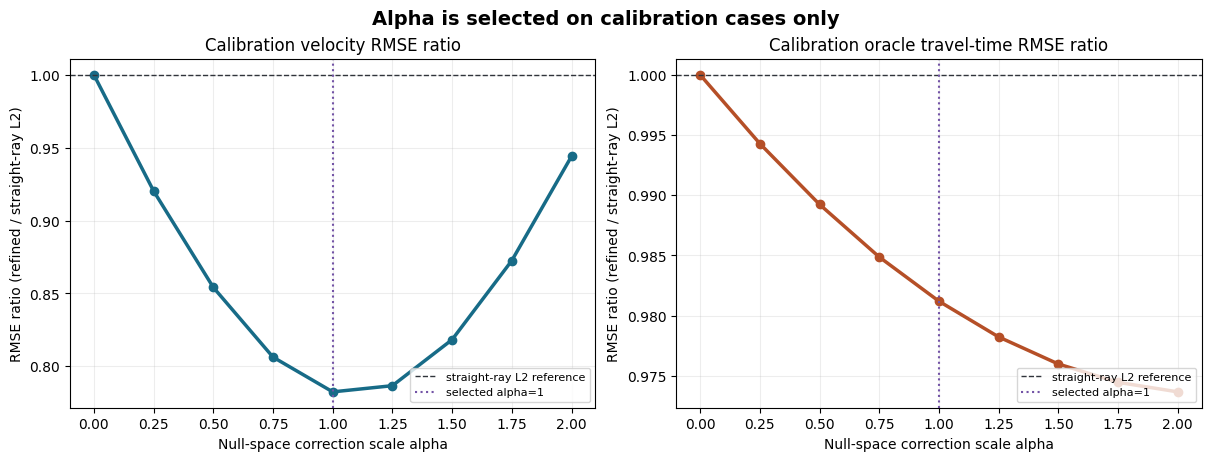

In [3]:
# Reproducible analysis cell.
# Plot the recorded calibration-only selection grid; do not inspect test outcomes for selection.
selection = analysis["calibration_selection"]
grid = selection["grid"]
alpha = np.array(sorted(float(x) for x in grid))
velocity = np.array([grid[str(x)]["velocity_ratio"] for x in alpha])
time = np.array([grid[str(x)]["oracle_time_ratio"] for x in alpha])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for axis, values, title, color in (
    (ax[0], velocity, "Calibration velocity RMSE ratio", "#176b87"),
    (ax[1], time, "Calibration oracle travel-time RMSE ratio", "#b54f27"),
):
    axis.plot(alpha, values, "o-", lw=2.5, color=color)
    axis.axhline(1, color="#30343b", lw=1, ls="--", label="straight-ray L2 reference")
    axis.axvline(
        selection["selected_alpha"],
        color="#7353a6",
        lw=1.5,
        ls=":",
        label=f"selected alpha={selection['selected_alpha']:g}",
    )
    axis.set(xlabel="Null-space correction scale alpha", ylabel="RMSE ratio (refined / straight-ray L2)", title=title)
    axis.grid(alpha=0.22)
    axis.legend(loc="lower right", frameon=True, fontsize=8)
fig.suptitle("Alpha is selected on calibration cases only", fontsize=14, fontweight="bold")


### The selected alpha is determined from the calibration grid, where both velocity and oracle-time ratios must satisfy the declared rule. The vertical marker records that choice; held-out outcomes do not tune it. A ratio below one means improvement against this straight-ray L2 reference for this metric and split, not a guarantee that refinement improves every realization.

El alpha seleccionado se determina desde la grilla de calibración, donde ambas razones de velocidad y tiempo oráculo deben cumplir la regla declarada. La línea vertical marca esa elección; los resultados de prueba no la ajustan. Una razón menor que uno indica mejora frente a esta base clásica para esta métrica y partición, no una garantía para cada realización.

In [4]:
# Keep alpha selection confined to calibration; held-out cohorts only measure its consequence.
plt.show()
print(
    "Selection rule:",
    selection["calibration_supported"],
    "— both metrics must improve; then minimize their mean ratio.",
)


Selection rule: True — both metrics must improve; then minimize their mean ratio.


### Experiment 3 — Inspect paired case outcomes

Edit `cohort_to_inspect` to examine the other fixed cohort. Each dot is one matched synthetic realization. Values below one indicate improvement over the straight-ray L2 reference for that metric.

The plotted values are recomputed from the notebook inputs and use the units named on the axes. The comparison shows the stated metric and split only; it cannot establish a unique subsurface, accuracy outside this data-generating process, or suitability for operational decisions. Read it together with the retained negative control and the limitations above.

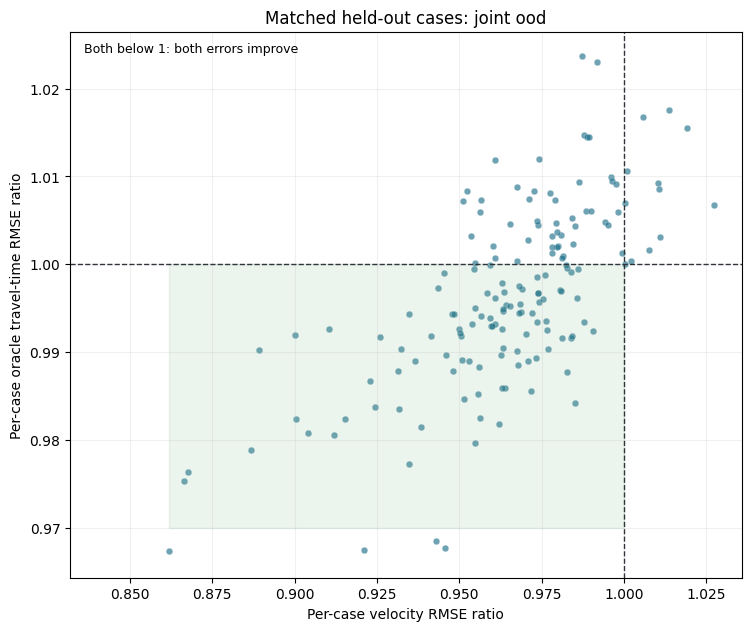

Median ratios: velocity=0.9683 oracle-time=0.9962
Cases improving both: 100 of 160


In [5]:
# Reproducible analysis cell.
cohort_to_inspect = "joint_ood"  # Change to id_test, family_only or acquisition_only and rerun this cell.
row = analysis["cohorts"][cohort_to_inspect]
x = np.asarray(row["velocity"]["case_ratios"], float)
y = np.asarray(row["oracle_time"]["case_ratios"], float)
fig, ax = plt.subplots(figsize=(7.4, 6.2), constrained_layout=True)
ax.scatter(x, y, s=23, alpha=0.62, c="#176b87", edgecolors="white", linewidths=0.25)
ax.axvline(1, color="#30343b", lw=1, ls="--")
ax.axhline(1, color="#30343b", lw=1, ls="--")
ax.fill_between(
    [max(0.5, float(x.min())), 1], [max(0.97, float(y.min()))] * 2, [1, 1], color="#64a77b", alpha=0.12
)
ax.set(
    xlabel="Per-case velocity RMSE ratio",
    ylabel="Per-case oracle travel-time RMSE ratio",
    title=f"Matched held-out cases: {cohort_to_inspect.replace('_',' ')}",
)
ax.grid(alpha=0.18)
ax.set_xlim(left=max(0.5, float(x.min()) - 0.03))
ax.set_ylim(bottom=min(0.97, float(y.min()) - 0.003))
ax.text(0.02, 0.98, "Both below 1: both errors improve", transform=ax.transAxes, va="top", fontsize=9)
plt.show()
print("Median ratios:", f"velocity={np.median(x):.4f}", f"oracle-time={np.median(y):.4f}")
print("Cases improving both:", int(np.sum((x < 1) & (y < 1))), "of", len(x))


### Each point is a paired held-out realization from the chosen cohort. Coordinates below one indicate that the refined model has lower error than its matched classical result; the quadrant count is more informative than the mean alone. These samples share one synthetic generator and are not independent evidence across geology or acquisition systems.

Cada punto representa una realización de prueba pareada de la cohorte elegida. Coordenadas menores que uno indican menor error del modelo refinado frente al resultado clásico correspondiente; el conteo por cuadrantes aporta más que la media sola. Las muestras comparten un generador sintético y no son evidencia independiente entre geologías o sistemas de adquisición.

In [6]:
# Keep alpha selection confined to calibration; held-out cohorts only measure its consequence.
print("These are per-realization ratios inside one synthetic generator, not uncertainty across geology.")


These are per-realization ratios inside one synthetic generator, not uncertainty across geology.


The plotted values are recomputed from the notebook inputs and use the units named on the axes. The comparison shows the stated metric and split only; it cannot establish a unique subsurface, accuracy outside this data-generating process, or suitability for operational decisions. Read it together with the retained negative control and the limitations above.

### Cohort calculation

This calculation groups the verified results by their declared case family. Counts retain failed and nonconverged runs; they do not establish field eligibility or optimizer recovery.


In [7]:
# Re-run the product receipt analysis and inspect the complete held-out cohort summaries.
analysis_repeat = analyze_receipt(receipt)
for cohort_name, cohort_values in analysis_repeat["cohorts"].items():
    print(
        cohort_name,
        "n",
        cohort_values["count"],
        "both improve",
        cohort_values["both_metrics_better_fraction"],
        "velocity ratio",
        cohort_values["velocity"]["aggregate_ratio"],
    )


id_test n 160 both improve 0.85 velocity ratio 0.803488502997178
family_only n 80 both improve 0.7 velocity ratio 0.9717635360245294
acquisition_only n 80 both improve 0.7375 velocity ratio 0.8023377559195833
joint_ood n 160 both improve 0.625 velocity ratio 0.9700567151783237


### Computed method output

This computes a case-family or paired-cohort statistic from verified inputs; it does not run or retune the inverse.


In [8]:
# Recompute paired effects for every held-out cohort.
for name, cohort in analysis["cohorts"].items():
    print(name, cohort["both_metrics_better_fraction"], cohort["count"])


id_test 0.85 160
family_only 0.7 80
acquisition_only 0.7375 80
joint_ood 0.625 160


### Computed method output

This computes a case-family or paired-cohort statistic from verified inputs; it does not run or retune the inverse.


In [9]:
# Inspect calibration choice without selecting from test results.
selection = analysis["calibration_selection"]
print("selected alpha", selection["selected_alpha"], "grid size", len(selection["grid"]))


selected alpha 1.0 grid size 9


### Computed method output

This computes a case-family or paired-cohort statistic from verified inputs; it does not run or retune the inverse.


In [10]:
# Count cases where both metrics improve in the selected cohort.
selected_cohort = analysis["cohorts"][cohort_to_inspect]
ratio_v = np.asarray(selected_cohort["velocity"]["case_ratios"])
ratio_t = np.asarray(selected_cohort["oracle_time"]["case_ratios"])
both_count = int(np.sum((ratio_v < 1) & (ratio_t < 1)))
print("both improve", both_count, "of", len(ratio_v))


both improve 100 of 160


### Build the bounded acquisition control

Recreate twelve cases from the declared joint-OOD family using the exact straight-ray operators. This small cohort exercises the production projector on physical velocity grids and noisy travel times; it is explicitly an algorithm control, not a new held-out estimate.


In [11]:
# Build the bounded synthetic control and obtain its physical ray operators.
import velocity_validation as velocity_physics
import velocity_nullspace_refinement_v11 as nullspace_method

ray_operators = velocity_physics.operators()
control_cohort = nullspace_method.make_cohort("joint_ood", ray_operators, fixture=True)
classical_control = velocity_physics.classical_predict(
    control_cohort, ray_operators, analysis["calibration_selection"]["selected_lambda"]
)
print("control cases", len(control_cohort["records"]), "grid", control_cohort["velocity"].shape[1:])


control cases 12 grid (16, 16)


### Calculate the acquisition null space

The basis is computed from the control's C-layout cell-length matrix, not inferred from the stored aggregate receipt. The residual check reports whether each basis vector is numerically invisible to that linearized straight-ray acquisition.


In [12]:
# Compute the orthonormal null-space basis for this acquisition matrix.
null_basis, null_basis_check = nullspace_method.nullspace_basis(ray_operators["C"]["cell"])
print("ray rank", null_basis_check["rank"], "nullity", null_basis_check["nullity"])
print("maximum A N residual", null_basis_check["max_abs_A_times_basis"])


ray rank 127 nullity 129
maximum A N residual 1.1503796922140982e-13


### Project a controlled residual correction

A smooth two-percent velocity perturbation supplies a transparent candidate correction so the projection itself can be examined without pretending that a trained checkpoint is present. The repository method maps the slowness difference into the acquisition null space and returns per-layout residual diagnostics.


In [13]:
# Apply the production correction projector to a declared smooth candidate.
space = np.linspace(-1.0, 1.0, velocity_physics.GRID)
pattern = np.broadcast_to(space[None, None, :], control_cohort["velocity"].shape)
controlled_prediction = classical_control * (1.0 + 0.02 * pattern)
projected_velocity, projection_check = nullspace_method.project_correction(
    control_cohort,
    classical_control,
    controlled_prediction,
    ray_operators,
    alpha=1.0,
    bases={"C": (null_basis, null_basis_check)},
)
print("projected shape", projected_velocity.shape)
print("projected residual", projection_check["C"]["max_abs_A_projected_correction"])


projected shape (12, 16, 16)
projected residual 1.328147661294743e-18


### Score the projected models with the forward operator

The scoring API computes both model-space velocity RMSE and oracle travel-time residuals against the same generated observations. The candidate is deliberately controlled rather than learned, so these numbers validate projection behavior only and must not be merged with the receipt's held-out model claims.


In [14]:
# Evaluate model and travel-time consequences on the same controlled cohort.
control_score = velocity_physics.score(
    control_cohort,
    projected_velocity,
    classical_control,
    ray_operators,
    float("inf"),
)
print("controlled velocity ratio", control_score["learned_to_classical_velocity_ratio"])
print("controlled oracle-time ratio", control_score["learned_to_classical_oracle_ratio"])


controlled velocity ratio 1.0216409467372431
controlled oracle-time ratio 1.0029545512705966
